# 06 qubit demos — on QCSS

Adapted from the official QICK demo [`06_qubit_demos.ipynb`](https://github.com/openquantumhardware/qick/blob/9d98886/qick_demos/06_qubit_demos.ipynb) (qick 0.2.370, MIT License, © 2021 Open Quantum Hardware).

Characterise a real qubit: time of flight, resonator spectroscopy, single-shot readout, qubit spectroscopy, Rabi, T1 and Ramsey. The upstream notebook was taken on its authors' ZCU111 wiring; here the same programs read out through this ZCU216 build's multiplexed readout generator, so their readout lines change (each marked `QCSS`), and the sweeps are shorter so the notebook runs in minutes.

**What changes from the official demo:** the two cells marked `QCSS` — starting the simulated board, and connecting through `make_proxy` instead of running on the board. Every other cell is the upstream code, unchanged except where a `QCSS` comment says so.

**What this shows:** qick's own client library compiles, uploads and acquires exactly as it does against a board, and gets back data of the shape, dtype and scale a board returns. It does **not** prove the numbers are identical to any particular physical board: no real-board reference data is compared here.

In [1]:
# QCSS: start the simulated ZCU216 board (tProc v1 firmware, as these demos expect)
import sys; sys.path.insert(0, '..')
import _lab, _proof
lab = _lab.start(qick=True, firmware='zcu216_v1_5q', loopback=())

Lab up: profile qick_zcu216_5q, device transmon_5q, QICK board zcu216_v1_5q


# <center>Qubit demos - working with a real qubit

The measurements in this notebook were used for the QICK paper https://arxiv.org/abs/2110.00557.
    
**These measurements were made a while ago, and the QICK API has changed a lot in the meantime. We try to keep this demo up to date and we make sure it runs, but we cannot guarantee that it still behaves correctly when connected to a real qubit.**
    
*It's recommended to look at the other demos to get an understanding of how the QICK programs in this demo work. You will learn things that you should know when writing your own programs.*

The following collections of QICK measurement code (shared by QICK collaborators) may also be helpful:
* [Connie Miao, Schuster Lab](https://github.com/conniemiao/slab_rfsoc_expts)
* [Chao Zhou, Hatlab](https://github.com/PITT-HATLAB/Hatlab_RFSOC)
* [Sara Sussman, Houck Lab](https://github.com/sarafs1926/qick-amo)


In [2]:
%pylab inline
from qick import *
from tqdm.notebook import tqdm

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


# Helper functions

In [3]:
#Figure params
rcParams['figure.figsize'] = 16, 8
rcParams.update({'font.size': 22})

#helper functions
def hist(data=None, plot=True, ran=1.0):
    
    ig = data[0]
    qg = data[1]
    ie = data[2]
    qe = data[3]

    numbins = 200
    
    xg, yg = np.median(ig), np.median(qg)
    xe, ye = np.median(ie), np.median(qe)

    if plot==True:
        fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
        fig.tight_layout()

        axs[0].scatter(ig, qg, label='g', color='b', marker='*')
        axs[0].scatter(ie, qe, label='e', color='r', marker='*')
        axs[0].scatter(xg, yg, color='k', marker='o')
        axs[0].scatter(xe, ye, color='k', marker='o')
        axs[0].set_xlabel('I (a.u.)')
        axs[0].set_ylabel('Q (a.u.)')
        axs[0].legend(loc='upper right')
        axs[0].set_title('Unrotated')
        axs[0].axis('equal')
    """Compute the rotation angle"""
    theta = -np.arctan2((ye-yg),(xe-xg))
    """Rotate the IQ data"""
    ig_new = ig*np.cos(theta) - qg*np.sin(theta)
    qg_new = ig*np.sin(theta) + qg*np.cos(theta) 
    ie_new = ie*np.cos(theta) - qe*np.sin(theta)
    qe_new = ie*np.sin(theta) + qe*np.cos(theta)
    
    """New means of each blob"""
    xg, yg = np.median(ig_new), np.median(qg_new)
    xe, ye = np.median(ie_new), np.median(qe_new)
    
    #print(xg, xe)
    
    xlims = [xg-ran, xg+ran]
    ylims = [yg-ran, yg+ran]

    if plot==True:
        axs[1].scatter(ig_new, qg_new, label='g', color='b', marker='*')
        axs[1].scatter(ie_new, qe_new, label='e', color='r', marker='*')
        axs[1].scatter(xg, yg, color='k', marker='o')
        axs[1].scatter(xe, ye, color='k', marker='o')    
        axs[1].set_xlabel('I (a.u.)')
        axs[1].legend(loc='lower right')
        axs[1].set_title('Rotated')
        axs[1].axis('equal')

        """X and Y ranges for histogram"""
        
        ng, binsg, pg = axs[2].hist(ig_new, bins=numbins, range = xlims, color='b', label='g', alpha=0.5)
        ne, binse, pe = axs[2].hist(ie_new, bins=numbins, range = xlims, color='r', label='e', alpha=0.5)
        axs[2].set_xlabel('I(a.u.)')       
        
    else:        
        ng, binsg = np.histogram(ig_new, bins=numbins, range = xlims)
        ne, binse = np.histogram(ie_new, bins=numbins, range = xlims)

    """Compute the fidelity using overlap of the histograms"""
    contrast = np.abs(((np.cumsum(ng) - np.cumsum(ne)) / (0.5*ng.sum() + 0.5*ne.sum())))
    tind=contrast.argmax()
    threshold=binsg[tind]
    fid = contrast[tind]
    axs[2].set_title(f"Fidelity = {fid*100:.2f}%")

    return fid, threshold, theta

In [4]:
# QCSS gap: this upstream cell is not run on QCSS; its code is kept below, commented out.
_proof.gap("the upstream authors' wiring photo is not included; the QCSS board's wiring is the ZCU216 description printed by print(soccfg)", 'src/qcss/boards/qick/firmware.py')

# from IPython.display import Image, display
# display(Image(filename='images/QICK_wiring_new.png', embed=True))

> ⚠️ **QCSS gap — skipped.** the upstream authors' wiring photo is not included; the QCSS board's wiring is the ZCU216 description printed by print(soccfg) (see `src/qcss/boards/qick/firmware.py`)

# Configuring the channels

The data in this notebook was taken with a wiring diagram similar to the above. The QICK has eight RF DACs which can be configured in multiple ways. Using the QICK, two RF DACs are needed to control the qubit and its readout resonator, respectively. Also, the qubit control pulses (< 6 GHz) were directly synthesized without the use of an analog mixer. Note that the QICK RF board was not used for these measurements, only the ZCU111 evaluation board plus the analog components specified in the diagram.

In [5]:
# Load bitstream with custom overlay
# QCSS: the official demo runs on the board itself (soc = QickSoc()). From a PC you reach a board through
# QICK's Pyro4 server instead (qick.pyro.make_proxy) -- on a real board only ns_host would differ.
from qick.pyro import make_proxy
soc, soccfg = make_proxy(ns_host="127.0.0.1", ns_port=8888, proxy_name="myqick")
_lab.keep_errors_visible()  # QCSS: make_proxy hides cell errors from Jupyter; keep them failing
# Since we're running locally on the QICK, we don't need a separate QickConfig object.
# If running remotely, you could generate a QickConfig from the QickSoc:
#     soccfg = QickConfig(soc.get_cfg())
# or save the config to file, and load it later:
#     with open("qick_config.json", "w") as f:
#         f.write(soc.dump_cfg())
#     soccfg = QickConfig("qick_config.json")

hw_cfg={"jpa_ch":6,
        "res_ch":10,  # QCSS: the feedline mux generator (on the authors' ZCU111: gen 5)
        "qubit_ch":0,  # QCSS: qubit 0's drive line
        "storage_ch":0
       }
readout_cfg={
    "readout_us": 3.0,  # QCSS: the probe length, us (the mux tone and the readout run on different clocks)
    "readout_length":soccfg.us2cycles(3.0, ro_ch=0), # [Clock ticks]
    "f_res": 7150.0, # [MHz]  QCSS: qubit 0's resonator, as specified
    "res_phase": 0,
    "adc_trig_offset": 275, # [Clock ticks]
    "res_gain":0.5  # QCSS: a mux tone's gain is a fraction of full scale
    }
qubit_cfg={
    "sigma":soccfg.us2cycles(0.025, gen_ch=0),
    "pi_gain": 7200,  # QCSS: this qubit's calibrated pi pulse (the amplitude Rabi below shows it)
    "pi2_gain":7200//2, 
    "f_ge":5050.0,  # QCSS: qubit 0, as specified
    "relax_delay":150  # QCSS: about 3x the specified T1
}

Pyro.NameServer PYRO:Pyro.NameServer@127.0.0.1:8888
myqick PYRO:obj_8e75f90e256f461cbdc8fbac7e50b38a@127.0.0.1:52213


# TOF Measurement

Measures the "time of flight" of the measurement pulse. The time of flight is the time at which the measurement pulse appears in the ADC buffer. We only want to start capturing data from this point in time onwards. We store this time of flight in the parameter <code> readout_cfg["adc_trig_offset"] </code>.

  0%|          | 0/1000 [00:00<?, ?it/s]

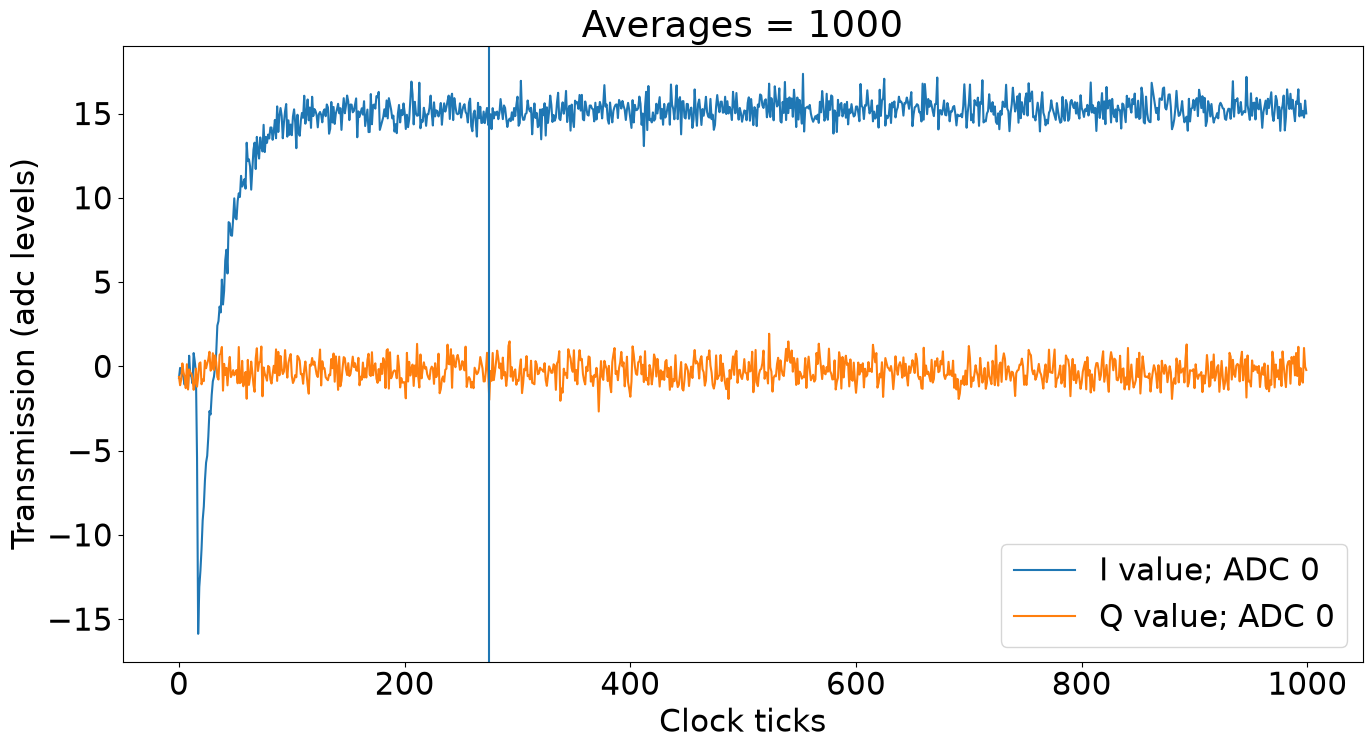

In [6]:
class LoopbackProgram(AveragerProgram):
    def initialize(self):
        cfg=self.cfg   
#         self.declare_gen(ch=cfg["jpa_ch"], nqz=1) #JPA
        self.declare_gen(ch=cfg["res_ch"], nqz=2, ro_ch=0, mux_freqs=[cfg.get("frequency", cfg["f_res"])],
                        mux_gains=[cfg["res_gain"]]) #Readout  # QCSS: a mux tone on the feedline
#         self.declare_gen(ch=cfg["qubit_ch"], nqz=2) #Qubit
#         self.declare_gen(ch=cfg["storage_ch"], nqz=2) #Storage

        for ch in [0]:  # QCSS: one readout, qubit 0's #configure the readout lengths and downconversion frequencies
            self.declare_readout(ch=ch, length=cfg["readout_length"],
                                 freq=cfg["frequency"], gen_ch=cfg["res_ch"])

        freq=self.freq2reg(cfg["frequency"], gen_ch=cfg["res_ch"], ro_ch=0)  # convert frequency to dac frequency (ensuring it is an available adc frequency)
        self.set_pulse_registers(ch=cfg["res_ch"], style="const", length=self.us2cycles(cfg["readout_us"], gen_ch=cfg["res_ch"]), mask=[0])  # QCSS: the mux tone (its freq and gain are in declare_gen)
        
        self.synci(200)  # give processor some time to configure pulses
    
    def body(self):
        cfg=self.cfg   
        self.measure(pulse_ch=cfg["res_ch"], 
             adcs=[0],
             adc_trig_offset=cfg["adc_trig_offset"],
             t=0,
             wait=True,
             syncdelay=self.us2cycles(cfg["relax_delay"]))        

expt_config={
        "reps":1, # --Fixed
        "pulse_length":600, # [Clock ticks]
        "readout_length":1000, # [Clock ticks]
        "pulse_gain":5000, # [DAC units]
        "frequency": 7150, # [MHz]  QCSS: at the resonator
        "adc_trig_offset": 0, # [Clock ticks]
        "soft_avgs":1000
       }

config={**hw_cfg,**readout_cfg,**qubit_cfg,**expt_config}
prog =LoopbackProgram(soccfg, config)
adc1, = prog.acquire_decimated(soc, progress=True)  # QCSS: one readout

# Plot results.
subplot(111, title=f"Averages = {config['soft_avgs']}", xlabel="Clock ticks", ylabel="Transmission (adc levels)")
plot(adc1[0], label="I value; ADC 0")
plot(adc1[1], label="Q value; ADC 0")
legend()
axvline(readout_cfg["adc_trig_offset"])

# Single tone (Resonator) Spectroscopy

Measures the resonant frequency of the readout resonator when the qubit is in its ground state. We store this resonant frequency in the parameter <code> readout_cfg["f_res"] </code>.

In [7]:
class SingleToneSpectroscopyProgram(AveragerProgram):
    def initialize(self):
        cfg=self.cfg   
        self.declare_gen(ch=cfg["res_ch"], nqz=2, ro_ch=0, mux_freqs=[cfg.get("frequency", cfg["f_res"])],
                        mux_gains=[cfg["res_gain"]]) #Readout  # QCSS: a mux tone on the feedline
        for ch in [0]:  # QCSS: one readout, qubit 0's #configure the readout lengths and downconversion frequencies
            self.declare_readout(ch=ch, length=cfg["readout_length"],
                                 freq=cfg["frequency"], gen_ch=cfg["res_ch"])
        
        freq=self.freq2reg(cfg["frequency"], gen_ch=cfg["res_ch"], ro_ch=0)  # convert frequency to dac frequency (ensuring it is an available adc frequency)
        self.set_pulse_registers(ch=cfg["res_ch"], style="const", length=self.us2cycles(cfg["readout_us"], gen_ch=cfg["res_ch"]), mask=[0])  # QCSS: the mux tone (its freq and gain are in declare_gen)

        self.synci(200)  # give processor some time to configure pulses
    
    def body(self):
        self.measure(pulse_ch=self.cfg["res_ch"], 
             adcs=[0],
             adc_trig_offset=self.cfg["adc_trig_offset"],
             wait=True,
             syncdelay=self.us2cycles(self.cfg["relax_delay"]))        

  0%|          | 0/60 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

... (51 outputs left out)

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

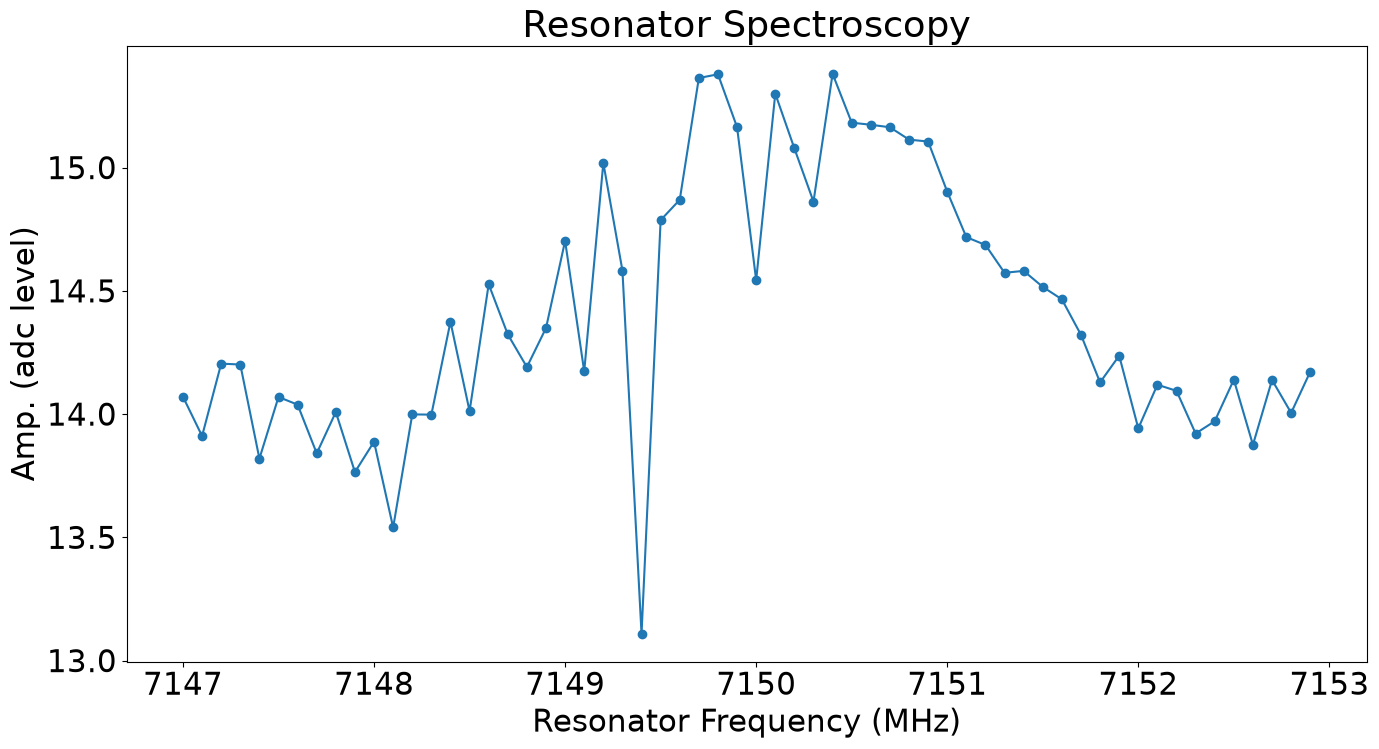

In [8]:
expt_cfg={"reps":200, "relax_delay":10,
          "start":7147, "step":0.1, "expts":60
         }
config={**hw_cfg,**readout_cfg,**qubit_cfg,**expt_cfg} #combine configs

fpts=expt_cfg["start"] + expt_cfg["step"]*np.arange(expt_cfg["expts"])

amps=[]
for f in tqdm(fpts):
    config["frequency"]=f

    rspec=SingleToneSpectroscopyProgram(soccfg, config)
    avgi,avgq=rspec.acquire(soc)
    amp=np.abs(avgi[0][0]+1j*avgq[0][0])
    amps.append(amp)
amps=np.array(amps)

plt.subplot(111,title="Resonator Spectroscopy", xlabel="Resonator Frequency (MHz)", ylabel="Amp. (adc level)")
plt.plot(fpts, amps,'o-')
max_freq=fpts[np.argmax(amps)]
plt.show()

# Single Shot

Measures the single shot readout fidelity of the system. We acquire single shot (I, Q) readout values by first preparing the qubit in its ground (blue dots) a certain number of times (in the below demo we take 5000 shots) and then preparing the qubit in its excited state (red dots) the same number of times. We then extract two parameters which are used to optimize the associated readout fidelity: the rotation angle of the IQ blobs and the threshold that classifies the two qubit states (ground and excited). We store these two parameters here <code> readout_cfg["res_phase"] </code> and <code> readout_cfg["threshold"] </code>.

Note that this experiment already assumes that you have found your qubit frequency and $\pi$ pulse amplitude. It is placed towards the top of this demo notebook because every time you reset the QICK firmware the single shot angle and threshold changes. So, this experiment is used to calibrate any experiment below that uses single shot data (such as the Active Reset experiment).

In [9]:
class SingleShotProgram(RAveragerProgram):
    def initialize(self):
        cfg=self.cfg
        
        self.declare_gen(ch=cfg["res_ch"], nqz=2, ro_ch=0, mux_freqs=[cfg.get("frequency", cfg["f_res"])],
                        mux_gains=[cfg["res_gain"]]) #Readout  # QCSS: a mux tone on the feedline
        self.declare_gen(ch=cfg["qubit_ch"], nqz=2) #Qubit
        for ch in [0]:  # QCSS: one readout, qubit 0's #configure the readout lengths and downconversion frequencies
            self.declare_readout(ch=ch, length=cfg["readout_length"],
                                 freq=cfg["f_res"], gen_ch=cfg["res_ch"], phase=cfg["res_phase"])

        cfg["start"]=0
        cfg["step"]=cfg["pi_gain"]
        cfg["reps"]=cfg["shots"]
        cfg["expts"]=2
        
        self.q_rp=self.ch_page(self.cfg["qubit_ch"])     # get register page for qubit_ch
        self.r_gain=self.sreg(cfg["qubit_ch"], "gain")   # get frequency register for qubit_ch    
        
        f_res=self.freq2reg(cfg["f_res"], gen_ch=cfg["res_ch"], ro_ch=0) # conver f_res to dac register value
        f_ge=self.freq2reg(cfg["f_ge"], gen_ch=cfg["qubit_ch"])
        
        # add qubit and readout pulses to respective channels
        self.add_gauss(ch=cfg["qubit_ch"], name="qubit", sigma=cfg["sigma"], length=cfg["sigma"]*4)
        self.set_pulse_registers(ch=cfg["qubit_ch"], style="arb", freq=f_ge, phase=0, gain=cfg["start"], 
                                 waveform="qubit")
        self.set_pulse_registers(ch=cfg["res_ch"], style="const", length=self.us2cycles(cfg["readout_us"], gen_ch=cfg["res_ch"]), mask=[0])  # QCSS: the mux tone (its freq and gain are in declare_gen)

        self.sync_all(self.us2cycles(500))
    
    def body(self):
        self.pulse(ch=self.cfg["qubit_ch"])  #play probe pulse
        self.sync_all(self.us2cycles(0.05)) # align channels and wait 50ns

        #trigger measurement, play measurement pulse, wait for qubit to relax
        self.measure(pulse_ch=self.cfg["res_ch"], 
             adcs=[0],
             adc_trig_offset=self.cfg["adc_trig_offset"],
             wait=True,
             syncdelay=self.us2cycles(self.cfg["relax_delay"]))
    
    def update(self):
        self.mathi(self.q_rp, self.r_gain, self.r_gain, '+', self.cfg["step"]) # update frequency list index
        
    def acquire(self,soc, progress=False):
        super().acquire(soc, progress=progress)
        return self.collect_shots()
        
    def collect_shots(self):
        # QCSS: since qick 0.2.x di_buf holds per-point averages; single shots come from get_raw() (raw sums,
        # in the same expts x reps order as before), so the original di_buf reshape fails on a real board too
        raw=self.get_raw()[0].reshape((self.cfg["expts"],self.cfg["reps"],2))/self.cfg['readout_length']
        shots_i0, shots_q0 = raw[:,:,0], raw[:,:,1]
        shots_i1, shots_q1 = shots_i0, shots_q0  # QCSS: one readout
        return shots_i0,shots_q0,shots_i1,shots_q1
        
    def analyze(self, shots_i, shots_q):
        plt.subplot(111, xlabel='I', ylabel='Q', title='Single Shot Histogram')
        plt.plot(shots_i[0],shots_q[0],'.',label='g')
        plt.plot(shots_i[1],shots_q[1],'.',label='e')
        plt.legend()
        plt.gca().set_aspect('equal', 'datalim')

  0%|          | 0/4000 [00:00<?, ?it/s]

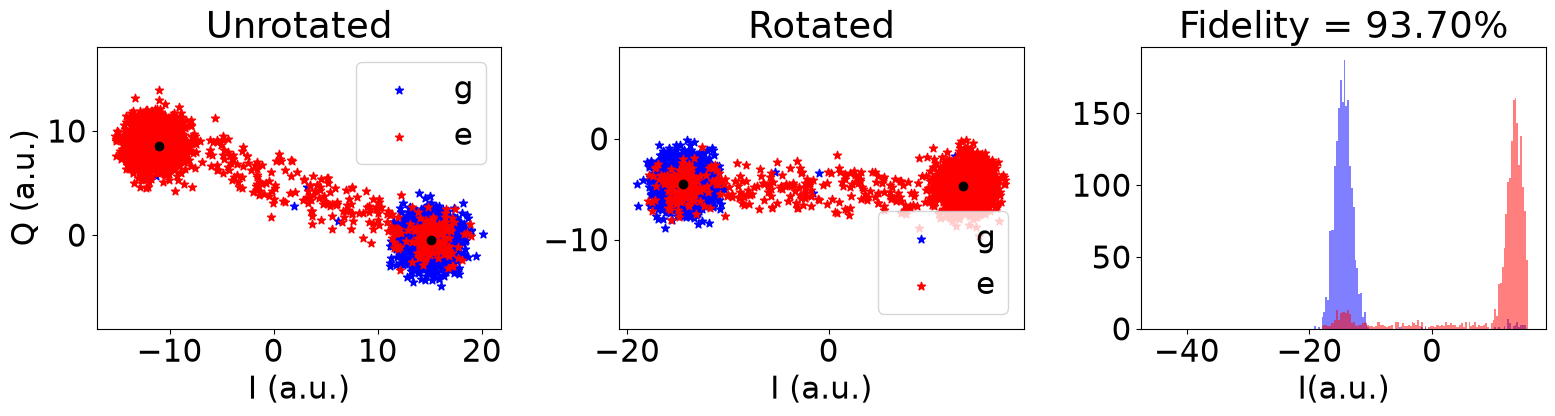

In [10]:
expt_cfg={
        "shots":2000, "res_phase":0
       }
config={**hw_cfg,**readout_cfg,**qubit_cfg,**expt_cfg} #combine configs

ssp=SingleShotProgram(soccfg, config)
di0, dq0, di1, dq1 = ssp.acquire(soc,progress=True)

fid, threshold, angle = hist(data=[di0[0], dq0[0], di0[1], dq0[1]],  plot=True, ran=30)  # QCSS: this board's blobs span ~20 ADC units, not ~600
#print('Optimal fidelity after rotation = %.3f' % fid)
readout_cfg["res_phase"]=-angle*180/pi  # QCSS: degrees, applied at the readout (a mux tone has no phase register)
readout_cfg["threshold"]=round(threshold)

# Pulse Probe (qubit) spectroscopy

Measures the qubit frequency f_ge. We store this parameter here: <code> qubit_cfg["f_ge"] </code>.

This program uses the RAveragerProgram class, which allows you to sweep a parameter directly on the processor rather than in a Python loop as in the above resonator spectroscopy example. Because the whole sweep is done on the processor there is less downtime (especially for fast experiments).

In [11]:
class PulseProbeSpectroscopyProgram(RAveragerProgram):
    def initialize(self):
        cfg=self.cfg
        
        self.declare_gen(ch=cfg["res_ch"], nqz=2, ro_ch=0, mux_freqs=[cfg.get("frequency", cfg["f_res"])],
                        mux_gains=[cfg["res_gain"]]) #Readout  # QCSS: a mux tone on the feedline
        self.declare_gen(ch=cfg["qubit_ch"], nqz=2) #Qubit
        for ch in [0]:  # QCSS: one readout, qubit 0's #configure the readout lengths and downconversion frequencies
            self.declare_readout(ch=ch, length=cfg["readout_length"],
                                 freq=cfg["f_res"], gen_ch=cfg["res_ch"], phase=cfg["res_phase"])

        self.q_rp=self.ch_page(self.cfg["qubit_ch"])     # get register page for qubit_ch
        self.r_freq=self.sreg(cfg["qubit_ch"], "freq")   # get frequency register for qubit_ch    
        
        f_res=self.freq2reg(cfg["f_res"], gen_ch=cfg["res_ch"], ro_ch=0) # conver f_res to dac register value

        self.f_start =self.freq2reg(cfg["start"], gen_ch=cfg["qubit_ch"])  # get start/step frequencies
        self.f_step =self.freq2reg(cfg["step"], gen_ch=cfg["qubit_ch"])

        # add qubit and readout pulses to respective channels
        self.set_pulse_registers(ch=cfg["qubit_ch"], style="const", freq=self.f_start, phase=0, gain=cfg["qubit_gain"], 
                                 length=cfg["probe_length"])
        self.set_pulse_registers(ch=cfg["res_ch"], style="const", length=self.us2cycles(cfg["readout_us"], gen_ch=cfg["res_ch"]), mask=[0])  # QCSS: the mux tone (its freq and gain are in declare_gen)
        
        self.sync_all(self.us2cycles(1))
    
    def body(self):
        self.pulse(ch=self.cfg["qubit_ch"])  #play probe pulse
        self.sync_all(self.us2cycles(0.05)) # align channels and wait 50ns

        #trigger measurement, play measurement pulse, wait for qubit to relax
        self.measure(pulse_ch=self.cfg["res_ch"], 
             adcs=[0],
             adc_trig_offset=self.cfg["adc_trig_offset"],
             wait=True,
             syncdelay=self.us2cycles(self.cfg["relax_delay"]))

    def update(self):
        self.mathi(self.q_rp, self.r_freq, self.r_freq, '+', self.f_step) # update frequency list index

  0%|          | 0/12000 [00:00<?, ?it/s]

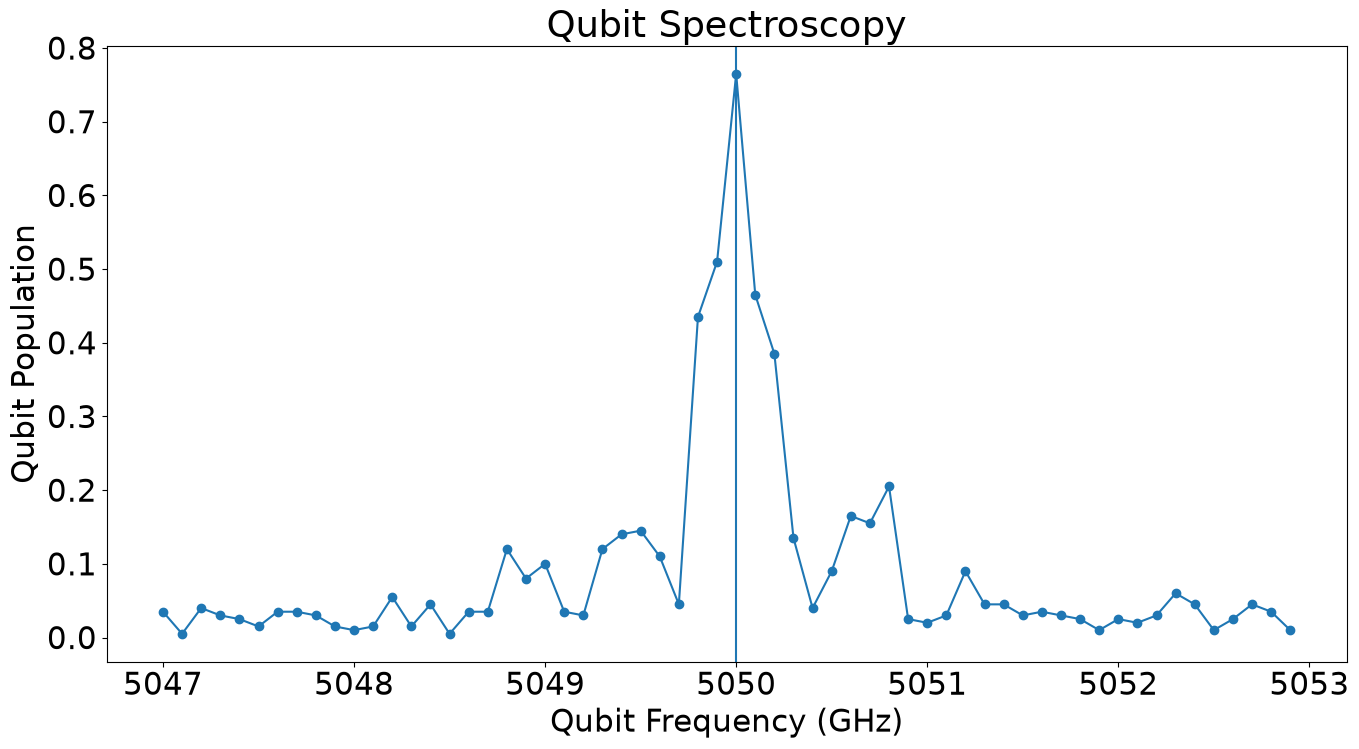

In [12]:
expt_cfg={"start":5047, "step":0.1, "expts":60, "reps": 200,"rounds":1,
          "probe_length":soccfg.us2cycles(2.0, gen_ch=0), "qubit_gain":200
         }
config={**hw_cfg,**readout_cfg,**qubit_cfg,**expt_cfg} #combine configs

qspec=PulseProbeSpectroscopyProgram(soccfg, config)
expt_pts, avgi, avgq = qspec.acquire(soc, threshold=readout_cfg["threshold"],progress=True)

subplot(111,title="Qubit Spectroscopy", xlabel="Qubit Frequency (GHz)", ylabel="Qubit Population")
plot(expt_pts, avgi[0][0],'o-')
axvline(qubit_cfg["f_ge"]);

In [13]:
# QCSS: keep the spectroscopy peak for the comparison with the true chip at the end
f_ge_measured = expt_pts[np.argmax(avgi[0][0])]
print(f'qubit spectroscopy peak: {f_ge_measured:.3f} MHz')

qubit spectroscopy peak: 5050.000 MHz


# Length Rabi

Measures Rabi oscillations by sweeping over the duration of the qubit drive pulse. This is a preliminary measurement to prove that we see Rabi oscillations. This measurement is followed up by the Amplitude Rabi experiment below.

Note that we could speed up this measurement by using an RAveragerProgram (tProcessor loop over duration) instead of a AveragerProgram with a Python loop. We would need to update two registers, one for the pulse length and one for the sync after playing the pulse (sync_all automatically accounts for the pulse length if it's a fixed value, but that doesn't work if the pulse length is being modified by the tProcessor).

In [14]:
class LengthRabiProgram(AveragerProgram):
    def initialize(self):
        cfg=self.cfg

        self.declare_gen(ch=cfg["res_ch"], nqz=2, ro_ch=0, mux_freqs=[cfg.get("frequency", cfg["f_res"])],
                        mux_gains=[cfg["res_gain"]]) #Readout  # QCSS: a mux tone on the feedline
        self.declare_gen(ch=cfg["qubit_ch"], nqz=2) #Qubit
        for ch in [0]:  # QCSS: one readout, qubit 0's #configure the readout lengths and downconversion frequencies
            self.declare_readout(ch=ch, length=cfg["readout_length"],
                                 freq=cfg["f_res"], gen_ch=cfg["res_ch"], phase=cfg["res_phase"])
        
        f_res=self.freq2reg(cfg["f_res"], gen_ch=cfg["res_ch"], ro_ch=0) # conver f_res to dac register value
        f_ge=self.freq2reg(cfg["f_ge"], gen_ch=cfg["qubit_ch"])

        # add qubit and readout pulses to respective channels
        self.set_pulse_registers(ch=cfg["qubit_ch"], style="const", freq=f_ge, phase=0, gain=cfg["qubit_gain"], 
                                 length=cfg["pulse_length"])
        self.set_pulse_registers(ch=cfg["res_ch"], style="const", length=self.us2cycles(cfg["readout_us"], gen_ch=cfg["res_ch"]), mask=[0])  # QCSS: the mux tone (its freq and gain are in declare_gen)

        self.synci(200)
        
    def body(self):
        cfg=self.cfg
        self.pulse(ch=cfg["qubit_ch"])  #play probe pulse
        self.sync_all(self.us2cycles(0.05)) # align channels and wait 50ns

        #trigger measurement, play measurement pulse, wait for qubit to relax
        self.measure(pulse_ch=cfg["res_ch"], 
             adcs=[0],
             wait=True,
             syncdelay=self.us2cycles(cfg["relax_delay"]))

  0%|          | 0/50 [00:00<?, ?it/s]

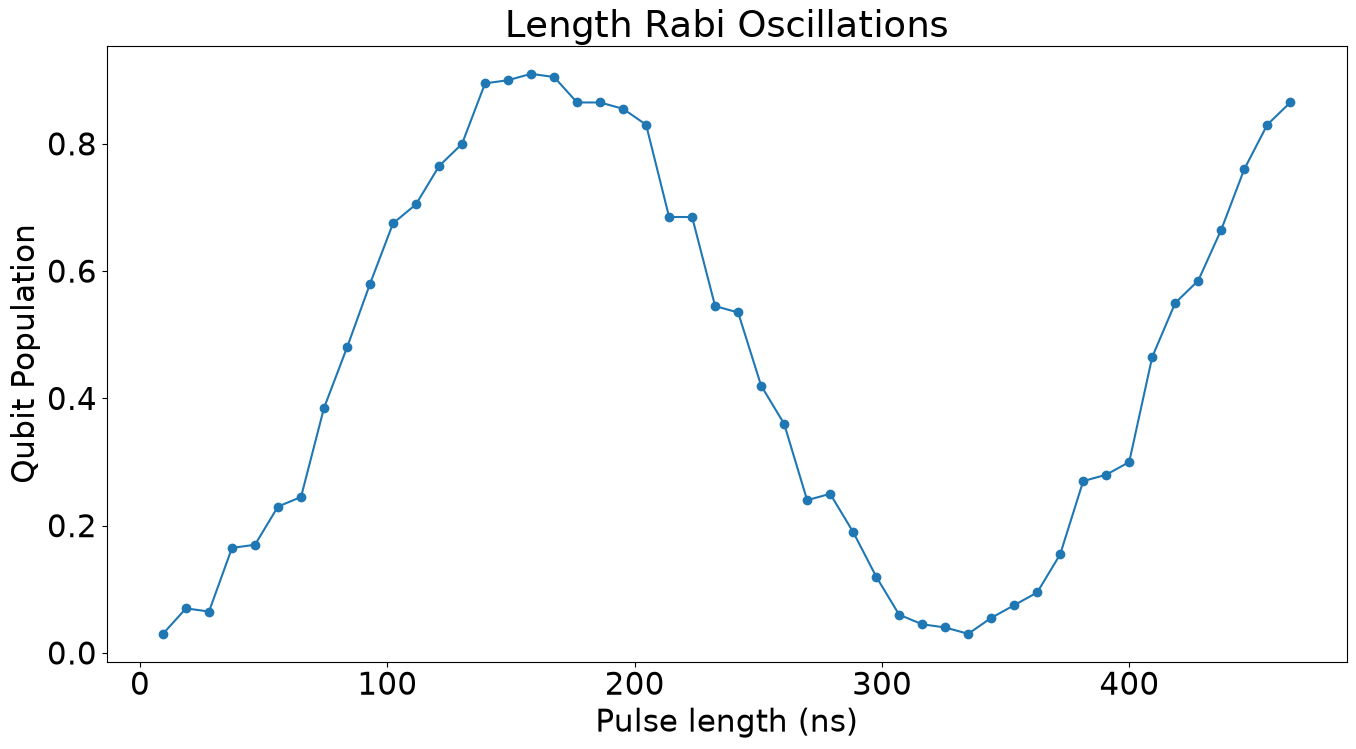

In [15]:
expt_cfg={
       "qubit_gain":2000,
        "start":4, "step":4, "expts":50, "reps": 200,
       }
config={**hw_cfg,**readout_cfg,**qubit_cfg,**expt_cfg} #combine configs
expt_pts=[expt_cfg["start"] + ii*expt_cfg["step"] for ii in range(expt_cfg["expts"])]


results=[]
for length in tqdm(expt_pts):
    config["pulse_length"]=length

    rabi=LengthRabiProgram(soccfg, config)
    avgi,avgq = rabi.acquire(soc, threshold=readout_cfg["threshold"], progress=False)
    results.append(avgi[0][0])
    
subplot(111, title="Length Rabi Oscillations", xlabel="Pulse length (ns)", ylabel="Qubit Population")
plot(soccfg.cycles2us(np.array(expt_pts), gen_ch=0)*1000,results,'o-');

# Amplitude Rabi

Measures Rabi oscillations by sweeping over the amplitude of the qubit drive pulse, which is an $\approx$ 100 ns ($\sigma$ $\approx$ 25 ns) long Gaussian pulse. We measure the $\pi$ and $\pi$/2 pulse amplitudes which are used in subsequent experiments to control the qubit. We store these parameters here: <code> qubit_cfg["pi_gain"] </code> and <code> qubit_cfg["pi2_gain"] </code>

In [16]:
class AmplitudeRabiProgram(RAveragerProgram):
    def initialize(self):
        cfg=self.cfg
        
        self.q_rp=self.ch_page(self.cfg["qubit_ch"])     # get register page for qubit_ch
        self.r_gain=self.sreg(cfg["qubit_ch"], "gain")   # get gain register for qubit_ch    
        
        self.declare_gen(ch=cfg["res_ch"], nqz=2, ro_ch=0, mux_freqs=[cfg.get("frequency", cfg["f_res"])],
                        mux_gains=[cfg["res_gain"]]) #Readout  # QCSS: a mux tone on the feedline
        self.declare_gen(ch=cfg["qubit_ch"], nqz=2) #Qubit
        for ch in [0]:  # QCSS: one readout, qubit 0's #configure the readout lengths and downconversion frequencies
            self.declare_readout(ch=ch, length=cfg["readout_length"],
                                 freq=cfg["f_res"], gen_ch=cfg["res_ch"], phase=cfg["res_phase"])
        
        f_res=self.freq2reg(cfg["f_res"], gen_ch=cfg["res_ch"], ro_ch=0) # conver f_res to dac register value
        f_ge=self.freq2reg(cfg["f_ge"], gen_ch=cfg["qubit_ch"])

        # add qubit and readout pulses to respective channels
        self.add_gauss(ch=cfg["qubit_ch"], name="qubit", sigma=cfg["sigma"], length=cfg["sigma"]*4)
        self.set_pulse_registers(ch=cfg["qubit_ch"], style="arb", freq=f_ge, phase=self.deg2reg(90, gen_ch=cfg["qubit_ch"]), gain=cfg["start"], 
                                 waveform="qubit")
        self.set_pulse_registers(ch=cfg["res_ch"], style="const", length=self.us2cycles(cfg["readout_us"], gen_ch=cfg["res_ch"]), mask=[0])  # QCSS: the mux tone (its freq and gain are in declare_gen)
        
        self.sync_all(self.us2cycles(500))
    
    def body(self):
        self.pulse(ch=self.cfg["qubit_ch"])  #play probe pulse
        self.sync_all(self.us2cycles(0.05)) # align channels and wait 50ns

        #trigger measurement, play measurement pulse, wait for qubit to relax
        self.measure(pulse_ch=self.cfg["res_ch"], 
             adcs=[0],
             adc_trig_offset=self.cfg["adc_trig_offset"],
             wait=True,
             syncdelay=self.us2cycles(self.cfg["relax_delay"]))
    
    def update(self):
        self.mathi(self.q_rp, self.r_gain, self.r_gain, '+', self.cfg["step"]) # update gain of the Gaussian pi pulse

<>:9: SyntaxWarning: invalid escape sequence '\s'
<>:9: SyntaxWarning: invalid escape sequence '\s'
C:\Users\pratu\AppData\Local\Temp\ipykernel_10256\1694350012.py:9: SyntaxWarning: invalid escape sequence '\s'
  subplot(111, title= f"Amplitude Rabi, $\sigma={soccfg.cycles2us(config['sigma'], gen_ch=0)*1000}$ ns", xlabel="Gain", ylabel="Qubit Population" )


  0%|          | 0/10000 [00:00<?, ?it/s]

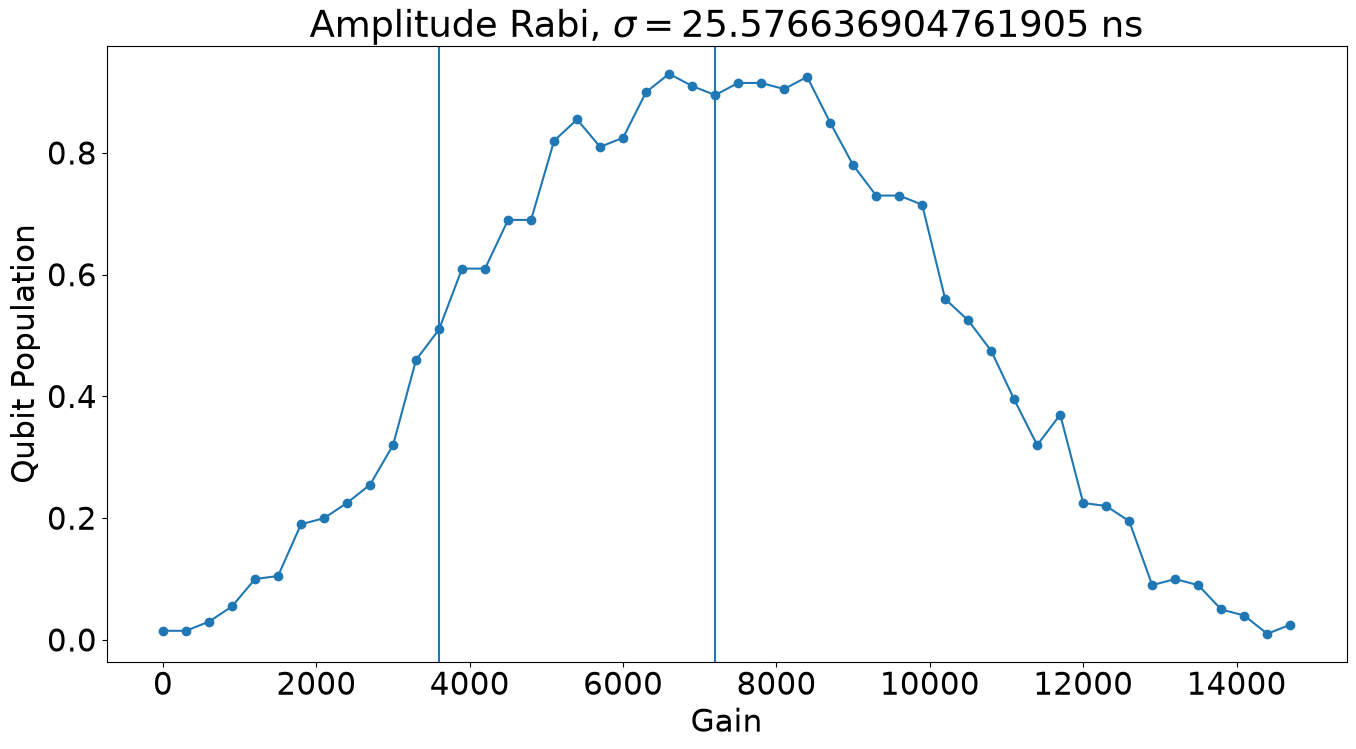

In [17]:
expt_cfg={
        "start":0, "step":300, "expts":50, "reps": 200
       }
config={**hw_cfg,**readout_cfg,**qubit_cfg,**expt_cfg} #combine configs

rabi=AmplitudeRabiProgram(soccfg, config)
x_pts, avgi, avgq  = rabi.acquire(soc,threshold=readout_cfg["threshold"],progress=True)

subplot(111, title= f"Amplitude Rabi, $\sigma={soccfg.cycles2us(config['sigma'], gen_ch=0)*1000}$ ns", xlabel="Gain", ylabel="Qubit Population" )
plot(x_pts,avgi[0][0],'o-')

axvline(qubit_cfg["pi_gain"])
axvline(qubit_cfg["pi2_gain"]);

# T1 

Measures the qubit T1 characteristic decay time by preparing the qubit in its excited state with a $\pi$ pulse followed by a variable delay ($\tau$) before measuring the qubit's state. This exponential decay curve can be fitted in post-processing to obtain the qubit T1 time.

In [18]:
class T1Program(RAveragerProgram):
    def initialize(self):
        cfg=self.cfg
        
        self.q_rp=self.ch_page(cfg["qubit_ch"])     # get register page for qubit_ch
        self.r_wait = 3
        self.regwi(self.q_rp, self.r_wait, cfg["start"])

        self.declare_gen(ch=cfg["res_ch"], nqz=2, ro_ch=0, mux_freqs=[cfg.get("frequency", cfg["f_res"])],
                        mux_gains=[cfg["res_gain"]]) #Readout  # QCSS: a mux tone on the feedline
        self.declare_gen(ch=cfg["qubit_ch"], nqz=2) #Qubit
        for ch in [0]:  # QCSS: one readout, qubit 0's #configure the readout lengths and downconversion frequencies
            self.declare_readout(ch=ch, length=cfg["readout_length"],
                                 freq=cfg["f_res"], gen_ch=cfg["res_ch"], phase=cfg["res_phase"])
        
        f_res=self.freq2reg(cfg["f_res"], gen_ch=cfg["res_ch"], ro_ch=0) # conver f_res to dac register value
        f_ge=self.freq2reg(cfg["f_ge"], gen_ch=cfg["qubit_ch"])

        # add qubit and readout pulses to respective channels
        self.add_gauss(ch=cfg["qubit_ch"], name="qubit", sigma=cfg["sigma"], length=cfg["sigma"]*4)
        self.set_pulse_registers(ch=cfg["qubit_ch"], style="arb", freq=f_ge, phase=0, gain=cfg["pi_gain"], 
                                 waveform="qubit")
        self.set_pulse_registers(ch=cfg["res_ch"], style="const", length=self.us2cycles(cfg["readout_us"], gen_ch=cfg["res_ch"]), mask=[0])  # QCSS: the mux tone (its freq and gain are in declare_gen)

        self.sync_all(self.us2cycles(500))
    
    def body(self):
        self.pulse(ch=self.cfg["qubit_ch"])  #play probe pulse
        self.sync_all()
        self.sync(self.q_rp,self.r_wait)

        #trigger measurement, play measurement pulse, wait for qubit to relax
        self.measure(pulse_ch=self.cfg["res_ch"], 
             adcs=[0],
             adc_trig_offset=self.cfg["adc_trig_offset"],
             wait=True,
             syncdelay=self.us2cycles(self.cfg["relax_delay"]))
    
    def update(self):
        self.mathi(self.q_rp, self.r_wait, self.r_wait, '+', self.us2cycles(self.cfg["step"])) # update frequency list index

<>:9: SyntaxWarning: invalid escape sequence '\m'
<>:9: SyntaxWarning: invalid escape sequence '\m'
C:\Users\pratu\AppData\Local\Temp\ipykernel_10256\1705126545.py:9: SyntaxWarning: invalid escape sequence '\m'
  subplot(111, title="T1 Experiment", xlabel=f"Time ($\mu s$)", ylabel="Qubit Population")


  0%|          | 0/10000 [00:00<?, ?it/s]

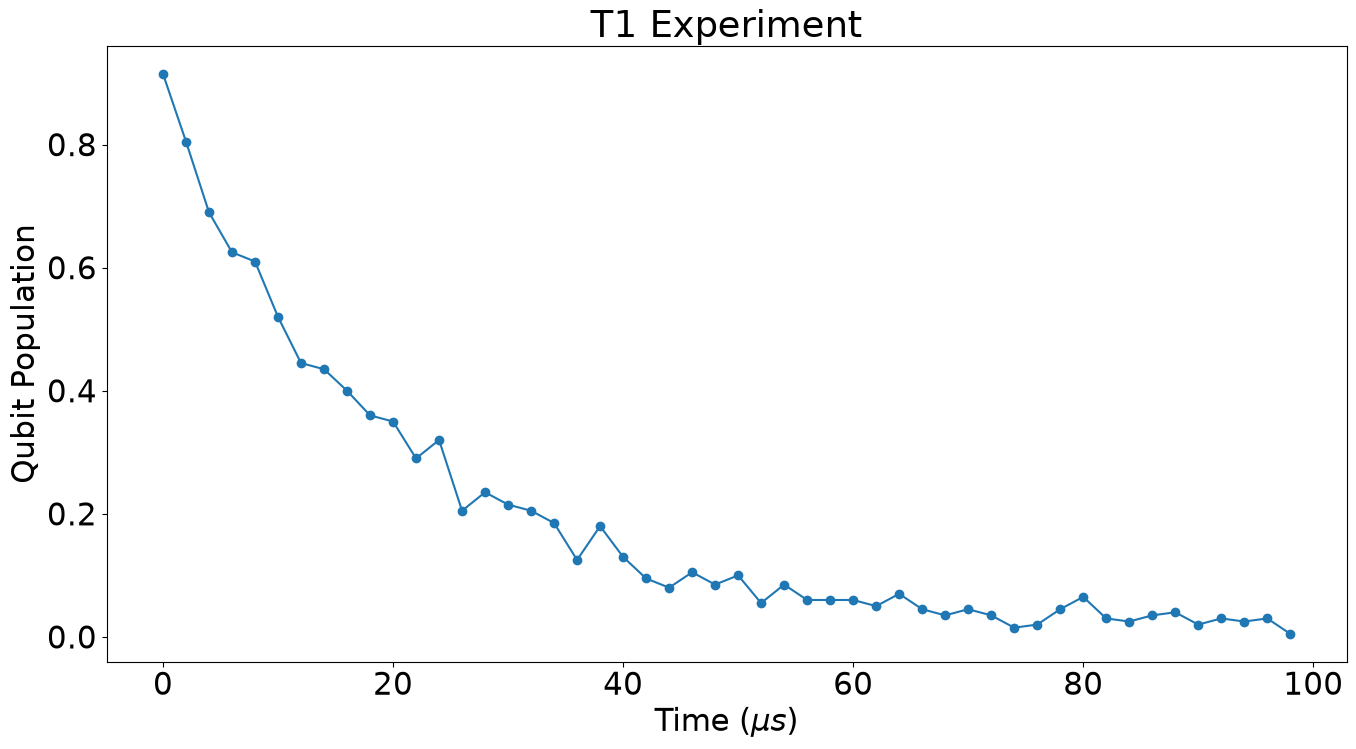

In [19]:
expt_cfg={ "start":0, "step":2, "expts":50, "reps": 200,
        "relax_delay":150
       }
config={**hw_cfg,**readout_cfg,**qubit_cfg,**expt_cfg} #combine configs

t1p=T1Program(soccfg, config)

x_pts, avgi, avgq = t1p.acquire(soc, threshold=readout_cfg["threshold"], progress=True)
subplot(111, title="T1 Experiment", xlabel=f"Time ($\mu s$)", ylabel="Qubit Population")
plot(x_pts, avgi[0][0],'o-');

In [20]:
# QCSS: fit T1 from the data above, for the comparison with the true chip at the end
from scipy.optimize import curve_fit
decay = lambda t, a, t1, c: a * np.exp(-t / t1) + c
(_, t1_measured, _), _ = curve_fit(decay, np.asarray(x_pts), np.asarray(avgi[0][0]), p0=(0.8, 20, 0.02))
print(f'fitted T1: {t1_measured:.1f} us')

fitted T1: 19.4 us


# Ramsey Fringe Experiment

Measures the qubit T2 Ramsey characteristic decay time by preparing the qubit in a superposition state with a  $\frac{\pi}{2}$ pulse followed by a variable delay ($\tau$) before applying another $\frac{\pi}{2}$ pulse with a phase advanced by $\Delta \phi = \omega * \tau$, where $\omega$ is the Ramsey frequency. This exponential decay envelope can be fitted in post-processing to obtain the qubit T2 Ramsey time.

In [21]:
class RamseyProgram(RAveragerProgram):
    def initialize(self):
        cfg=self.cfg
        
        self.q_rp=self.ch_page(cfg["qubit_ch"])     # get register page for qubit_ch
        self.r_wait = 3
        self.r_phase2 = 4
        self.r_phase=self.sreg(cfg["qubit_ch"], "phase")
        self.regwi(self.q_rp, self.r_wait, cfg["start"])
        self.regwi(self.q_rp, self.r_phase2, 0)
        
        self.declare_gen(ch=cfg["res_ch"], nqz=2, ro_ch=0, mux_freqs=[cfg.get("frequency", cfg["f_res"])],
                        mux_gains=[cfg["res_gain"]]) #Readout  # QCSS: a mux tone on the feedline
        self.declare_gen(ch=cfg["qubit_ch"], nqz=2) #Qubit
        for ch in [0]:  # QCSS: one readout, qubit 0's #configure the readout lengths and downconversion frequencies
            self.declare_readout(ch=ch, length=cfg["readout_length"],
                                 freq=cfg["f_res"], gen_ch=cfg["res_ch"], phase=cfg["res_phase"])
        
        f_res=self.freq2reg(cfg["f_res"], gen_ch=cfg["res_ch"], ro_ch=0) # conver f_res to dac register value
        f_ge=self.freq2reg(cfg["f_ge"], gen_ch=cfg["qubit_ch"])

        # add qubit and readout pulses to respective channels
        self.add_gauss(ch=cfg["qubit_ch"], name="qubit", sigma=cfg["sigma"], length=cfg["sigma"]*4)
        self.set_pulse_registers(ch=cfg["qubit_ch"], style="arb", freq=f_ge, phase=0, gain=cfg["pi2_gain"], 
                                 waveform="qubit")
        self.set_pulse_registers(ch=cfg["res_ch"], style="const", length=self.us2cycles(cfg["readout_us"], gen_ch=cfg["res_ch"]), mask=[0])  # QCSS: the mux tone (its freq and gain are in declare_gen)        
        
        self.sync_all(self.us2cycles(0.2))
    
    def body(self):
        self.regwi(self.q_rp, self.r_phase, 0)
        
        self.pulse(ch=self.cfg["qubit_ch"])  #play probe pulse
        self.mathi(self.q_rp, self.r_phase, self.r_phase2,"+",0)
        self.sync_all()
        self.sync(self.q_rp,self.r_wait)

        self.pulse(ch=self.cfg["qubit_ch"])  #play probe pulse
        self.sync_all(self.us2cycles(0.05))

        #trigger measurement, play measurement pulse, wait for qubit to relax
        self.measure(pulse_ch=self.cfg["res_ch"], 
             adcs=[0],
             adc_trig_offset=self.cfg["adc_trig_offset"],
             wait=True,
             syncdelay=self.us2cycles(self.cfg["relax_delay"]))
        
    def update(self):
        self.mathi(self.q_rp, self.r_wait, self.r_wait, '+', self.cfg["step"]) # update the time between two π/2 pulses
        self.mathi(self.q_rp, self.r_phase2, self.r_phase2, '+', self.cfg["phase_step"]) # advance the phase of the LO for the second π/2 pulse

<>:8: SyntaxWarning: invalid escape sequence '\m'
<>:8: SyntaxWarning: invalid escape sequence '\m'
C:\Users\pratu\AppData\Local\Temp\ipykernel_10256\918458856.py:8: SyntaxWarning: invalid escape sequence '\m'
  subplot(111, title="Ramsey Fringe Experiment", xlabel="Delay time ($\mu$s)", ylabel="Qubit Population")


  0%|          | 0/12000 [00:00<?, ?it/s]

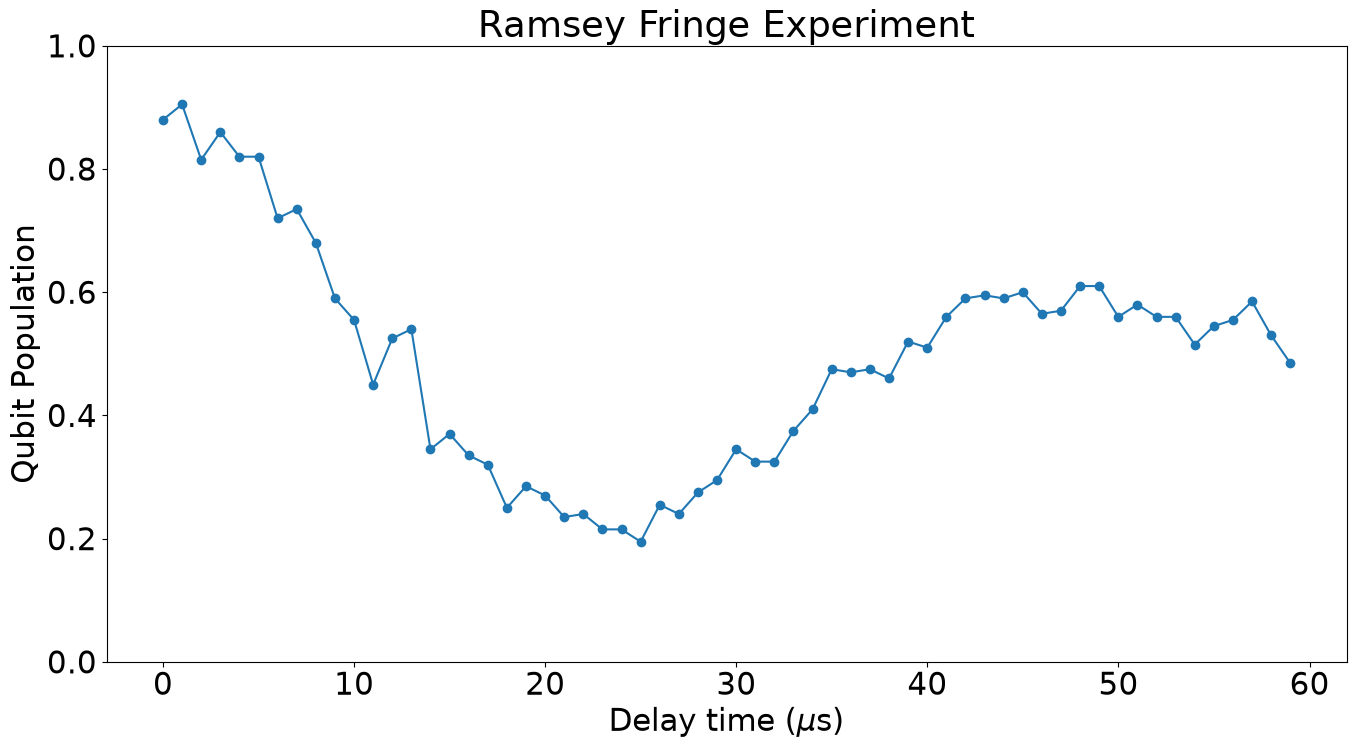

In [22]:
expt_cfg={"start":soccfg.us2cycles(0.0), "step":soccfg.us2cycles(1), "phase_step": soccfg.deg2reg(2*360/100, gen_ch=0), "expts":60,
          "reps": 200, "rounds": 1
       }
config={**hw_cfg,**readout_cfg,**qubit_cfg,**expt_cfg} #combine configs
t2p=RamseyProgram(soccfg, config)
x_pts, avgi, avgq= t2p.acquire(soc, threshold=readout_cfg["threshold"],progress=True)

subplot(111, title="Ramsey Fringe Experiment", xlabel="Delay time ($\mu$s)", ylabel="Qubit Population")
plot(soccfg.cycles2us(x_pts),avgi[0][0],'o-')
ylim(0,1);

# Active reset

This experiment demonstrates active reset with the QICK. 

The protocol is as follows: there is an overall loop over the qubit drive pulse amplitude (as in the amplitude Rabi measurement above). During each loop iteration, several measurements occur. First, an amplitude rabi measurement is done (labeled "pre-reset" in the below plot). If that measurement doesn't exceed a threshold (meaning that the qubit is in its ground state after the qubit drive pulse was applied) nothing is done. But if the measurement exceeds the threshold (meaning that the the qubit is in its excited state after the qubit drive pulse was applied) a $\pi$ pulse is applied to the qubit (hopefully bringing it back to the gnd state). Finally, a second measurement is done (labeled "post-reset" in the below plot). 

Note that to run this experiment you must first successfully calibrate the single-shot readout threshold using the Single Shot experiment above. 

In [23]:
# QCSS gap: this upstream cell is not run on QCSS; its code is kept below, commented out.
_proof.gap('active reset branches on a measurement inside the program (measurement feedback), which QCSS does not simulate yet', 'notebooks/README.md')

# class ActiveResetProgram(RAveragerProgram):        
#     def initialize(self):
#         cfg=self.cfg
#         
#         self.q_rp=self.ch_page(self.cfg["qubit_ch"])     # get register page for qubit_ch
#         self.r_gain=self.sreg(cfg["qubit_ch"], "gain")   # get frequency register for qubit_ch  
#         
#         self.r_gain2=4
#         self.regwi(self.q_rp, self.r_gain2, cfg["start"])        
# 
#         self.r_thresh = 6
#         self.regwi(0,self.r_thresh,config["threshold"]*cfg["readout_length"])
#         
#         self.declare_gen(ch=cfg["res_ch"], nqz=2, ro_ch=0, mux_freqs=[cfg.get("frequency", cfg["f_res"])],
#                         mux_gains=[cfg["res_gain"]]) #Readout  # QCSS: a mux tone on the feedline
#         self.declare_gen(ch=cfg["qubit_ch"], nqz=2) #Qubit
#         for ch in [0]:  # QCSS: one readout, qubit 0's #configure the readout lengths and downconversion frequencies
#             self.declare_readout(ch=ch, length=cfg["readout_length"],
#                                  freq=cfg["f_res"], gen_ch=cfg["res_ch"], phase=cfg["res_phase"])
#         
#         f_res=self.freq2reg(cfg["f_res"], gen_ch=cfg["res_ch"], ro_ch=0) # conver f_res to dac register value
#         f_ge=self.freq2reg(cfg["f_ge"], gen_ch=cfg["qubit_ch"])
# 
#         # add qubit and readout pulses to respective channels
#         self.add_gauss(ch=cfg["qubit_ch"], name="qubit", sigma=cfg["sigma"], length=cfg["sigma"]*4)
#         self.set_pulse_registers(ch=cfg["qubit_ch"], style="arb", freq=f_ge, phase=0, gain=cfg["start"], 
#                                  waveform="qubit")
#         self.set_pulse_registers(ch=cfg["res_ch"], style="const", length=self.us2cycles(cfg["readout_us"], gen_ch=cfg["res_ch"]), mask=[0])  # QCSS: the mux tone (its freq and gain are in declare_gen)        
#         
#         self.sync_all(self.us2cycles(500))
#     
#     def body(self):
#         self.mathi(self.q_rp,self.r_gain,self.r_gain2,"+",0)
#         
#         self.pulse(ch=self.cfg["qubit_ch"])  #play probe pulse
#         self.sync_all(self.us2cycles(0.05))
#         
#         self.measure(pulse_ch=self.cfg["res_ch"], 
#              adcs=[0],
#              adc_trig_offset=self.cfg["adc_trig_offset"])
#         
#         self.wait_all(200) # pause until 200 clocks past the end of the readout window
#         self.read(0,0,"lower",2)
#         self.read(0,0,"upper",3)
#         self.condj(0,2,'<',self.r_thresh,'after_reset')
# 
#         self.regwi(self.q_rp, self.r_gain, self.cfg["pi_gain"])  #pi pulse qubit
#         self.pulse(ch=self.cfg["qubit_ch"], t=0)
# 
#         self.label('after_reset')
#         self.sync_all(self.us2cycles(1)) # align channels and wait 50ns
# 
#         #trigger measurement, play measurement pulse, wait for qubit to relax
#         self.measure(pulse_ch=self.cfg["res_ch"], 
#              adcs=[0],
#              adc_trig_offset=self.cfg["adc_trig_offset"],
#              wait=True,
#              syncdelay=self.us2cycles(self.cfg["relax_delay"]))
# 
#     def update(self):
#         self.mathi(self.q_rp, self.r_gain2, self.r_gain2, '+', self.cfg["step"]) # update frequency list index
#         

> ⚠️ **QCSS gap — skipped.** active reset branches on a measurement inside the program (measurement feedback), which QCSS does not simulate yet (see `notebooks/README.md`)

In [24]:
# QCSS gap: this upstream cell is not run on QCSS; its code is kept below, commented out.
_proof.gap('active reset branches on a measurement inside the program (measurement feedback), which QCSS does not simulate yet', 'notebooks/README.md')

# expt_cfg={
#         "start":0, "step":100, "expts":300, "reps": 400
#        }
# config={**hw_cfg,**readout_cfg,**qubit_cfg,**expt_cfg} #combine configs
# 
# areset=ActiveResetProgram(soccfg, config)
# expt_pts,avgi,avgq = areset.acquire(soc, threshold=readout_cfg["threshold"], progress=True)
# 
# subplot(111,title="Active Reset", xlabel="Pulse Amplitude", ylabel="Qubit Population")
# plot(expt_pts,avgi[0][0],'o-', label="pre-reset")
# plot(expt_pts,avgi[0][1], 'o-', label="post-reset")
# legend();

> ⚠️ **QCSS gap — skipped.** active reset branches on a measurement inside the program (measurement feedback), which QCSS does not simulate yet (see `notebooks/README.md`)

## Does the client think it is a real board?

In [25]:
_proof.qick_surface(soc, soccfg)

client: Pyro4 proxy to 'obj_8e75f90e256f461cbdc8fbac7e50b38a' at 127.0.0.1
board, as qick describes it:
  QICK running on ZCU216, software version 0.2.370
  
  Firmware configuration (built Tue Mar 10 14:22:05 2026):
remote surface: 25 of the real board's 76 methods served, none extra  ✓


## What QCSS adds: the true chip

A real lab never learns what its qubit really is: it only has fits. QCSS can say. `lab.truth()` reads the simulated chip through the admin channel (which a client of the board never sees). The chip drifts slowly (flux noise, two-level defects), so the truth is read now, right after the measurements; the frequency tolerance covers that drift, the T1 tolerance the statistics of a 50-point sweep.

In [26]:
truth = lab.truth()[0]
_proof.truth_table([
    ('qubit 0 f01 (MHz)', f_ge_measured, truth['frequency_hz'] / 1e6, 1e-4),
    ('qubit 0 T1 (us)', t1_measured, truth['t1_s'] * 1e6, 0.35),
])

quantity                          measured    true (admin)     error     tol
qubit 0 f01 (MHz)                     5050         5050.03    0.00%      0%  ✓
qubit 0 T1 (us)                    19.3711         18.8977    2.51%     35%  ✓


## Teardown

In [27]:
lab.stop()